In [2]:

import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

df = pd.read_csv("../data/processed/telco_customer_churn_clean.csv")
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# Create the preprocessing steps
xgb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

# Learn the encoding from training data and transform both datasets
X_train_xgb = xgb_preprocessor.fit_transform(X_train)
X_test_xgb = xgb_preprocessor.transform(X_test)

# Keep feature names for later interpretation with SHAP
feature_names = xgb_preprocessor.get_feature_names_out()

X_train_xgb = pd.DataFrame(
    X_train_xgb, columns=feature_names, index=X_train.index
)
X_test_xgb = pd.DataFrame(
    X_test_xgb, columns=feature_names, index=X_test.index
)

print("Training data shape:", X_train_xgb.shape)
print("Test data shape:", X_test_xgb.shape)


Training data shape: (5634, 45)
Test data shape: (1409, 45)


In [3]:

from xgboost import XGBClassifier

# Calculate the ratio of non-churners to churners
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Scale positive weight:", round(scale_weight, 2))

# Create the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_xgb, y_train)

print("XGBoost model trained successfully!")


Scale positive weight: 2.77
XGBoost model trained successfully!


In [4]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Predict churn labels and probabilities
xgb_pred = xgb_model.predict(X_test_xgb)
xgb_proba = xgb_model.predict_proba(X_test_xgb)[:, 1]

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, xgb_pred), 4))
print("Precision:", round(precision_score(y_test, xgb_pred), 4))
print("Recall:", round(recall_score(y_test, xgb_pred), 4))
print("F1-score:", round(f1_score(y_test, xgb_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, xgb_proba), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_test, xgb_proba), 4))

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))


Accuracy: 0.7516
Precision: 0.5217
Recall: 0.7701
F1-score: 0.622
ROC-AUC: 0.8398
PR-AUC (Average Precision): 0.6574

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.74      0.82      1035
           1       0.52      0.77      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409

Confusion Matrix:
[[771 264]
 [ 86 288]]


In [5]:

import shap
import matplotlib.pyplot as plt

# Create an explainer for the trained XGBoost model
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values for the test data
shap_values = explainer(X_test_xgb)

print("SHAP values calculated successfully!")
print("SHAP values shape:", shap_values.values.shape)


SHAP values calculated successfully!
SHAP values shape: (1409, 45)


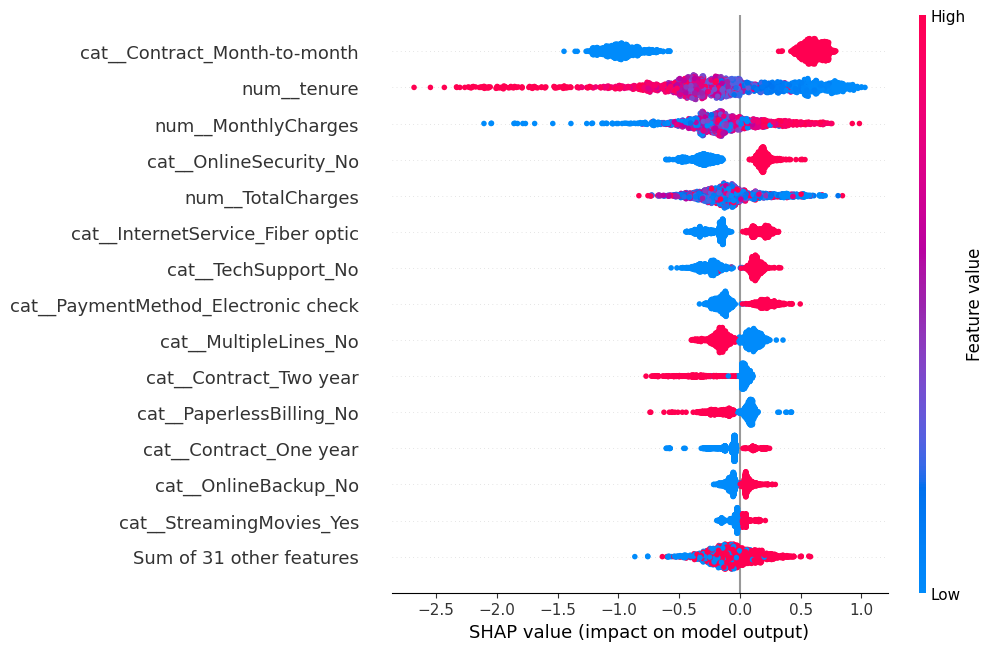

In [6]:

shap.plots.beeswarm(shap_values, max_display=15)


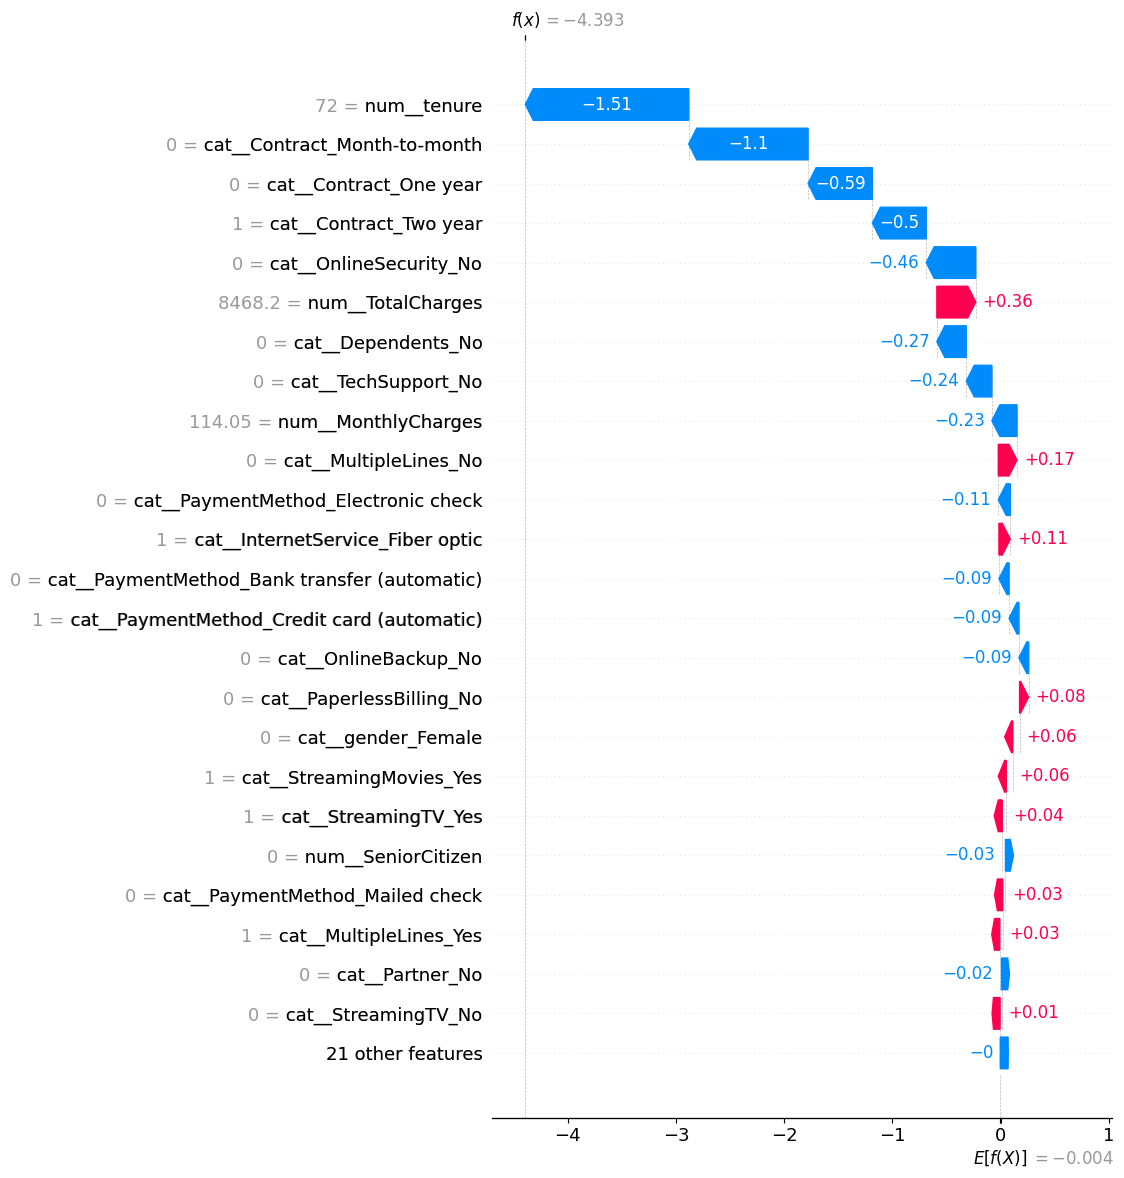

In [8]:

# Select the first customer in the test set
customer_index = 0

# Show how each feature contributed to this customer's prediction
shap.plots.waterfall(shap_values[customer_index], max_display=25)


In [9]:

import pandas as pd
import numpy as np

# Create a table of actual churn and predicted churn risk
risk_df = pd.DataFrame({
    "Actual_Churn": y_test.to_numpy(),
    "Churn_Probability": xgb_proba
})

# Sort customers from highest to lowest predicted risk
risk_df = risk_df.sort_values(
    by="Churn_Probability",
    ascending=False
).reset_index(drop=True)

# Select the top 10% highest-risk customers
top_10_count = int(np.ceil(len(risk_df) * 0.10))
top_10 = risk_df.head(top_10_count)

# Calculate how many actual churners are in this group
total_churners = risk_df["Actual_Churn"].sum()
churners_in_top_10 = top_10["Actual_Churn"].sum()
churner_capture = churners_in_top_10 / total_churners

print("Total test customers:", len(risk_df))
print("Customers in top 10%:", len(top_10))
print("Actual churners in test set:", total_churners)
print("Churners in top 10%:", churners_in_top_10)
print("Share of churners captured in top 10%:",
      f"{churner_capture:.1%}")


Total test customers: 1409
Customers in top 10%: 141
Actual churners in test set: 374
Churners in top 10%: 109
Share of churners captured in top 10%: 29.1%
